Top-15 plates: ['Pacific', 'Antarctica', 'Africa', 'North America', 'Eurasia', 'Australia', 'South America', 'Somalia', 'Nazca', 'India', 'Sunda', 'Philippine Sea', 'Amur', 'Arabia', 'Okhotsk', 'Caribbean', 'Cocos']


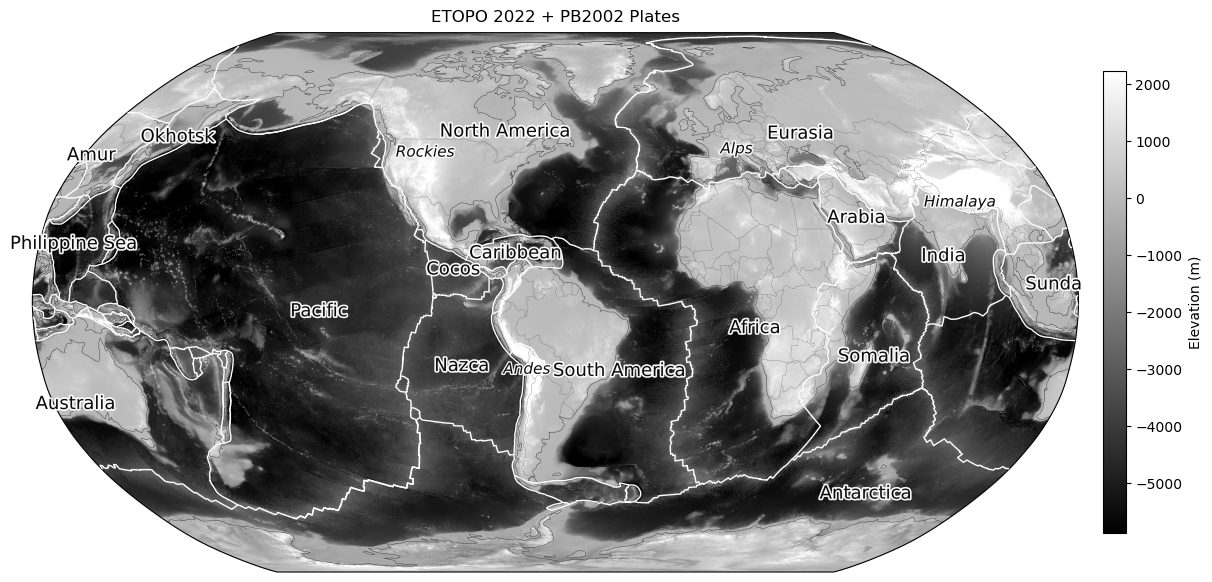

In [1]:
from __future__ import annotations

from pathlib import Path
from typing import Iterable, Optional

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from matplotlib import patheffects as pe

PLATE_CARREE = ccrs.PlateCarree()
# Robinson projection with central_longitude = -90
ROBINSON = ccrs.Robinson(central_longitude=-60)


def _pick_name_field(gdf: gpd.GeoDataFrame) -> str:
    for c in ("PlateName", "PLATE_NAME", "NAME", "Name", "plate_name", "Plate"):
        if c in gdf.columns:
            return c
    return next(c for c in gdf.columns if c.lower() != "geometry")


def top_n_plate_names_by_area(
    polygons_path: str | Path, top_n: int = 15
) -> list[str]:
    gdf0 = gpd.read_file(polygons_path).to_crs(4326)
    name_field = _pick_name_field(gdf0)
    gdf = gdf0[[name_field, "geometry"]].dissolve(by=name_field, as_index=False)
    gdf["area_km2"] = gdf.to_crs(6933).area / 1e6
    gdf_sorted = gdf.sort_values("area_km2", ascending=False)
    return gdf_sorted[name_field].head(top_n).tolist()


def plot_etopo_robinson_tiff(
    etopo_path: str | Path,
    cmap: str = "gray",
    vmin: Optional[float] = None,
    vmax: Optional[float] = None,
    title: Optional[str] = "ETOPO 2022 + PB2002 Plates",
    figsize: tuple[int, int] = (12, 6.5),
    target_max_dim: int = 6000,
):
    fig = plt.figure(figsize=figsize, constrained_layout=True)
    ax = plt.axes(projection=ROBINSON)
    ax.set_global()

    with rasterio.open(etopo_path) as src:
        max_dim = max(src.width, src.height)
        scale = max(1, int(np.ceil(max_dim / target_max_dim)))
        out_h = max(1, src.height // scale)
        out_w = max(1, src.width // scale)

        data = src.read(1, out_shape=(out_h, out_w))
        if src.nodata is not None:
            data = np.ma.masked_equal(data, src.nodata)
        data = np.ma.masked_invalid(data)

        if vmin is None or vmax is None:
            finite = np.asarray(data)[np.isfinite(data)]
            lo, hi = np.percentile(finite, [1, 99])
            vmin = lo if vmin is None else vmin
            vmax = hi if vmax is None else vmax

        left, bottom, right, top = src.bounds
        extent = (left, right, bottom, top)

        im = ax.imshow(
            data,
            extent=extent,
            transform=PLATE_CARREE,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            origin="upper",
            zorder=1,
            rasterized=True,
        )

    cbar = plt.colorbar(im, ax=ax, shrink=0.72, pad=0.02)
    cbar.set_label("Elevation (m)")

    ax.coastlines(color="0.2", linewidth=0.3, zorder=2)
    ax.add_feature(
        cfeature.BORDERS.with_scale("110m"),
        edgecolor="0.4",
        linewidth=0.2,
        zorder=2,
    )
    if title:
        ax.set_title(title, pad=8)
    return fig, ax


def add_plate_boundaries(
    ax: plt.Axes,
    boundaries_path: str | Path,
    color: str = "w",  # white
    lw: float = 1.0,   # thicker
):
    gdf = gpd.read_file(boundaries_path).to_crs(4326)
    gdf.plot(
        ax=ax,
        transform=PLATE_CARREE,
        edgecolor=color,
        facecolor="none",
        linewidth=lw,
        zorder=10,
    )


def add_plate_labels_topn(
    ax: plt.Axes,
    polygons_path: str | Path,
    keep_names: Iterable[str],
    name_field: Optional[str] = "PlateName",
    textsize: int = 12,
    textcolor: str = "k",
    halo: bool = True,
):
    gdf0 = gpd.read_file(polygons_path).to_crs(4326)
    if (name_field is None) or (name_field not in gdf0.columns):
        name_field = _pick_name_field(gdf0)

    gdf = gdf0[[name_field, "geometry"]].dissolve(by=name_field, as_index=False)
    gdf = gdf[gdf[name_field].astype(str).isin({str(n) for n in keep_names})].copy()

    reps = gdf.geometry.representative_point()
    effects = [pe.withStroke(linewidth=2.4, foreground="w")] if halo else None

    for pt, name in zip(reps, gdf[name_field]):
        if pt.is_empty:
            continue
        ax.text(
            pt.x,
            pt.y,
            str(name),
            transform=PLATE_CARREE,
            ha="center",
            va="center",
            fontsize=textsize,
            color=textcolor,
            alpha=0.96,
            zorder=11,
            path_effects=effects,
        )

def add_range_labels(ax: plt.Axes):
    """
    Add italicized labels for major mountain ranges.
    Adjust coordinates as needed for aesthetics.
    """
    ranges = {
        "Andes": (-70, -20),       # lon, lat
        "Himalaya": (85, 30),
        "Alps": (10, 46),
        "Rockies": (-110, 45),
    }

    for label, (lon, lat) in ranges.items():
        ax.text(
            lon,
            lat,
            label,
            transform=PLATE_CARREE,
            ha="center",
            va="center",
            fontsize=11,
            color="k",
            fontstyle="italic",
            alpha=0.95,
            zorder=12,
            path_effects=[pe.withStroke(linewidth=2, foreground="w")],
        )

etopo_file = "ETOPO_2022_v1_60s_N90W180_bed.tif"
plates_file = "tectonicplates/PB2002_plates.shp"
boundaries_file = "tectonicplates/PB2002_boundaries.shp"

# Compute top-15 by area
top15 = top_n_plate_names_by_area(plates_file, top_n=17)
print("Top-15 plates:", top15)

fig, ax = plot_etopo_robinson_tiff(etopo_file)
add_plate_boundaries(ax, boundaries_file, color="w", lw=1.0)
add_plate_labels_topn(ax, plates_file, keep_names=top15, textsize=13, halo=True)

add_range_labels(ax)

plt.savefig("etopo_plates_ranges.png", dpi=600)
plt.show()

Top-15 plates: ['Pacific', 'Antarctica', 'Africa', 'North America', 'Eurasia', 'Australia', 'South America', 'Somalia', 'Nazca', 'India', 'Sunda', 'Philippine Sea', 'Amur', 'Arabia', 'Okhotsk', 'Caribbean', 'Cocos']


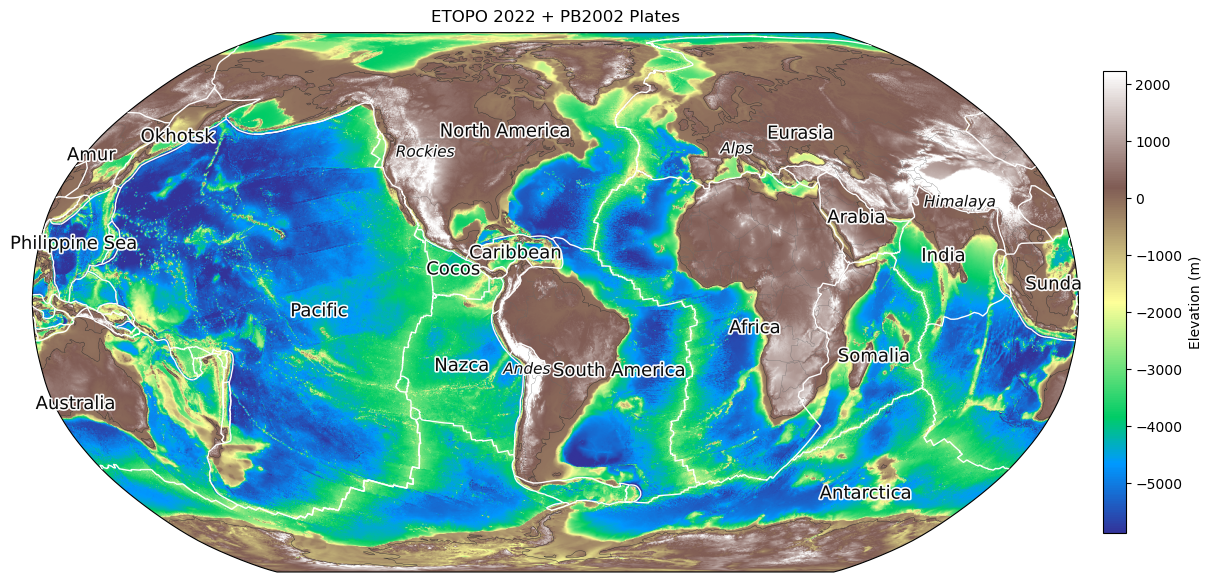

In [2]:
# Compute top-15 by area
top15 = top_n_plate_names_by_area(plates_file, top_n=17)
print("Top-15 plates:", top15)

fig, ax = plot_etopo_robinson_tiff(etopo_file, cmap="terrain")
add_plate_boundaries(ax, boundaries_file, color="w", lw=1.0)
add_plate_labels_topn(ax, plates_file, keep_names=top15, textsize=13, halo=True)

add_range_labels(ax)

plt.savefig("etopo_plates_ranges.png", dpi=600)
plt.show()